# 8. Partial least squares for soft sensors

Partial least squares (PLS) chooses its components to covary with the quantity to be predicted, which is why it is the usual method for calibrating spectrometers. The lecture follows the NIPALS algorithm step by step, checks its orthogonality relations, and compares it with principal component regression and with the minimum-norm least-squares solution on synthetic spectra with more channels than samples.

## Learning objectives

1. Follow the NIPALS algorithm of partial least squares for one response (`dim_reduction.pls1_nipals`).
2. Check that the score vectors are mutually orthogonal and that the regression vector follows from the weights and loadings.
3. Compare PLS with minimum-norm least squares and with principal component regression on synthetic spectra of 120 channels and 35 samples.
4. Choose the number of latent variables from the error on data kept out of the fit.

**Time:** about 60 min

In [1]:
try:                      # use the installed package, or the copy in this repository
    import engml_2_applied
except ImportError:
    import pathlib, subprocess, sys
    for _root in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]:
        if (_root / "engml_2_applied" / "__init__.py").exists():
            sys.path.insert(0, str(_root))
            break
    else:                 # on Google Colab: install from GitHub
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "git+https://github.com/ktwyw/engml-2-applied.git"], check=True)
    import engml_2_applied

import inspect
import numpy as np
import matplotlib.pyplot as plt
from engml_2_applied import (clustering_phases, constants, descriptors, dim_reduction, linear_physics,
                             trees_ensembles, uncertainty)
from engml_2_applied.plotting import panel_label, use_style

use_style()

def show_source(obj):
    """Return the source code of a library function or class."""
    return inspect.getsource(obj)

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## 1. Principles and governing equations
Given centered spectral matrix $\mathbf{E}_0 = \mathbf{X} - \mathbf{1}_N\bar{\mathbf{x}}^\top \in \mathbb{R}^{N \times d}$ and centered concentration vector $\mathbf{f}_0 = \mathbf{y} - \bar{y}\mathbf{1}_N \in \mathbb{R}^N$, **Wold's NIPALS PLS1 algorithm (Wold et al., 1984)** extracts $k$ supervised latent variables sequentially ($a = 1, \dots, k$). At stage $a$, the weight vector $\mathbf{w}_a \in \mathbb{R}^d$ maximizes the empirical covariance $\mathbf{w}_a^\top \mathbf{E}_{a-1}^\top \mathbf{f}_{a-1}$ subject to $\|\mathbf{w}_a\|_2 = 1$:
$$\mathbf{w}_a = \frac{\mathbf{E}_{a-1}^\top \mathbf{f}_{a-1}}{\|\mathbf{E}_{a-1}^\top \mathbf{f}_{a-1}\|_2}, \qquad \mathbf{t}_a = \mathbf{E}_{a-1}\mathbf{w}_a \in \mathbb{R}^N \tag{1.1}$$
Next, both $\mathbf{E}_{a-1}$ and $\mathbf{f}_{a-1}$ are regressed onto the score vector $\mathbf{t}_a$ and deflated by rank-1 projections:
$$\mathbf{p}_a = \frac{\mathbf{E}_{a-1}^\top \mathbf{t}_a}{\mathbf{t}_a^\top \mathbf{t}_a}, \qquad q_a = \frac{\mathbf{f}_{a-1}^\top \mathbf{t}_a}{\mathbf{t}_a^\top \mathbf{t}_a}, \qquad \mathbf{E}_a = \mathbf{E}_{a-1} - \mathbf{t}_a\mathbf{p}_a^\top, \qquad \mathbf{f}_a = \mathbf{f}_{a-1} - q_a\mathbf{t}_a \tag{1.2}$$
This deflation guarantees mutually orthogonal latent scores $\mathbf{t}_a^\top \mathbf{t}_b = 0$ ($a \ne b$) and upper-triangular $\mathbf{P}^\top\mathbf{W}$, yielding the exact regression vector in the original $d$-wavelength coordinate frame:
$$\hat{\boldsymbol{\beta}}_{\mathrm{PLS}} = \mathbf{W}\left(\mathbf{P}^\top\mathbf{W}\right)^{-1}\mathbf{q} \in \mathbb{R}^d, \qquad \hat{\beta}_0 = \bar{y} - \bar{\mathbf{x}}^\top\hat{\boldsymbol{\beta}}_{\mathrm{PLS}} \tag{1.3}$$

In [2]:
heading("Demonstration 1: Wold NIPALS PLS1 on a 120-Wavelength NIR Soft Sensor (d = 120 >> N = 35)")
rng = np.random.default_rng(42)
N, d = 35, 120
wl = np.linspace(1100.0, 2300.0, d)
# 3 overlapping chemical chromophores (water, methanol, ethanol):
E_pure = np.vstack([
    np.exp(-0.5 * ((wl - 1450.0) / 60.0) ** 2) + 0.4 * np.exp(-0.5 * ((wl - 1940.0) / 50.0) ** 2),
    np.exp(-0.5 * ((wl - 1680.0) / 55.0) ** 2) + 0.6 * np.exp(-0.5 * ((wl - 2100.0) / 45.0) ** 2),
    np.exp(-0.5 * ((wl - 1720.0) / 50.0) ** 2) + 0.5 * np.exp(-0.5 * ((wl - 2150.0) / 55.0) ** 2),
])
C_conc = rng.uniform(0.05, 0.95, size=(N, 3))
X_nir = C_conc @ E_pure + rng.normal(0.0, 0.008, size=(N, d))
y_meoh = C_conc[:, 1] + rng.normal(0.0, 0.06, size=N)

pls3 = dim_reduction.pls1_nipals(X_nir, y_meoh, n_components=3)
T_scores = pls3["scores"]
G_scores = T_scores.T @ T_scores
off_diag = G_scores - np.diag(np.diag(G_scores))
print("Score inner-product matrix T^T T:\n", np.round(G_scores, 4))
print("Max off-diagonal score inner product:", float(np.max(np.abs(off_diag))))
assert np.max(np.abs(off_diag)) < 1e-11


Demonstration 1: Wold NIPALS PLS1 on a 120-Wavelength NIR Soft Sensor (d = 120 >> N = 35)
Score inner-product matrix T^T T:
 [[52.5149 -0.     -0.    ]
 [-0.      4.0175  0.    ]
 [-0.      0.     21.9306]]
Max off-diagonal score inner product: 2.412018188547328e-15


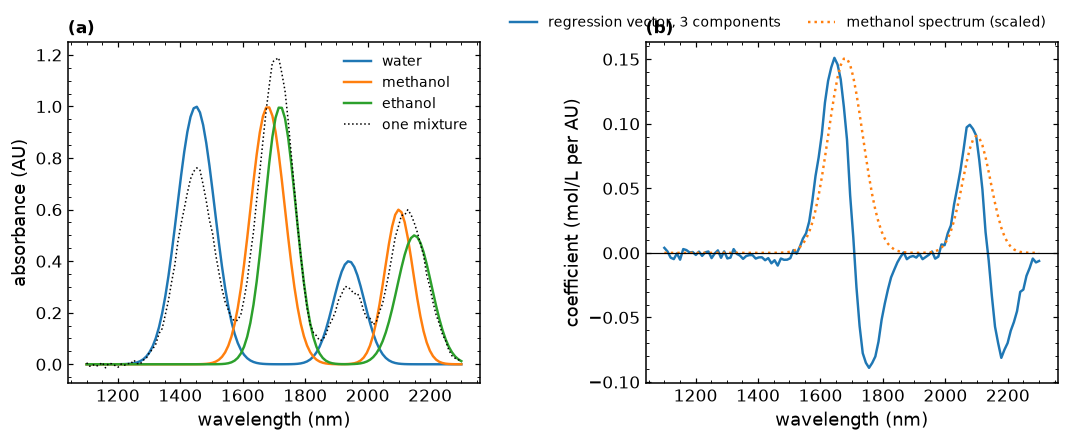

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.6, 3.9))
for j, name in enumerate(["water", "methanol", "ethanol"]):
    ax1.plot(wl, E_pure[j], label=name)
ax1.plot(wl, X_nir[0], ":", color="k", lw=1.0, label="one mixture")
ax1.set_xlabel("wavelength (nm)"); ax1.set_ylabel("absorbance (AU)"); ax1.legend(fontsize=9); ax1.set_title("(a)", loc="left", fontweight="bold")
ax2.plot(wl, pls3["coef"], "-", color="C0", label="regression vector, 3 components")
ax2.plot(wl, E_pure[1] * np.max(np.abs(pls3["coef"])), ":", color="C1", label="methanol spectrum (scaled)")
ax2.axhline(0.0, color="k", lw=0.8)
ax2.set_xlabel("wavelength (nm)"); ax2.set_ylabel("coefficient (mol/L per AU)"); ax2.legend(fontsize=9, loc="lower right", bbox_to_anchor=(1.0, 1.0), ncol=2); ax2.set_title("(b)", loc="left", fontweight="bold")
plt.show()

**Figure 8.1.** (a) The synthetic pure spectra of three overlapping absorbers and one of the 35 mixture spectra. (b) The regression vector of the PLS model for methanol. It is positive on the side of each methanol band away from ethanol and negative on the ethanol side, which is how a linear model subtracts an interfering species whose bands overlap.

**What Demonstration 1 shows.** There are $d = 120$ channels and $N = 35$ calibration samples, so $\mathbf{X}^\top\mathbf{X}$ has at least $85$ zero eigenvalues and cannot be inverted. The NIPALS algorithm does not need the inverse: it extracts three score vectors that are mutually orthogonal ($\mathbf{T}^\top\mathbf{T}$ is diagonal to $10^{-14}$).

---

## 2. Numerical walkthrough
Let us trace the rank-1 deflation loop step by step across stages $a = 1, 2, 3$, tracking the remaining spectral Frobenius energy $\|\mathbf{E}_a\|_F^2$, remaining target variance $\|\mathbf{f}_a\|_2^2$, and the upper-bidiagonal structure of $\mathbf{P}^\top\mathbf{W}$.

In [4]:
heading("Demonstration 2: Step-by-Step NIPALS Deflation Energy & P^T W Structure")
E_curr = X_nir - np.mean(X_nir, axis=0)
f_curr = y_meoh - float(np.mean(y_meoh))
e0_norm = float(np.sum(E_curr ** 2))
f0_norm = float(np.sum(f_curr ** 2))
W_m, P_m = np.zeros((d, 3)), np.zeros((d, 3))
for a in range(3):
    w_a = E_curr.T @ f_curr
    w_a /= np.linalg.norm(w_a)
    t_a = E_curr @ w_a
    p_a = (E_curr.T @ t_a) / float(t_a @ t_a)
    q_a = float(f_curr @ t_a) / float(t_a @ t_a)
    E_curr = E_curr - np.outer(t_a, p_a)
    f_curr = f_curr - q_a * t_a
    W_m[:, a], P_m[:, a] = w_a, p_a
    print(f"After LV {a+1} | Spectral X variance captured = {100*(1 - np.sum(E_curr**2)/e0_norm):6.2f}% | Target y variance captured = {100*(1 - np.sum(f_curr**2)/f0_norm):6.2f}%")
print("\nUpper-triangular matrix P^T W:\n", np.round(P_m.T @ W_m, 6))
assert np.allclose(np.tril(P_m.T @ W_m, -1), 0.0, atol=1e-12) and np.allclose(np.diag(P_m.T @ W_m), 1.0, atol=1e-12)


Demonstration 2: Step-by-Step NIPALS Deflation Energy & P^T W Structure
After LV 1 | Spectral X variance captured =  67.37% | Target y variance captured =  57.14%
After LV 2 | Spectral X variance captured =  72.83% | Target y variance captured =  93.60%
After LV 3 | Spectral X variance captured =  99.71% | Target y variance captured =  94.34%

Upper-triangular matrix P^T W:
 [[ 1.       -0.220939  0.      ]
 [ 0.        1.       -0.332648]
 [ 0.       -0.        1.      ]]


**What Demonstration 2 shows.** The matrix $\mathbf{P}^\top\mathbf{W}$ is upper bidiagonal with ones on its diagonal ($\mathbf{p}_a^\top\mathbf{w}_a = 1$, and $(\mathbf{P}^\top\mathbf{W})_{ab} = 0$ for $a > b$), so its inverse in the formula for the regression vector always exists.

---

## 3. Worked case study
Let us compare 3-component PLS1 against unregularized minimum-norm OLS (`np.linalg.lstsq`) on an independent 40-sample validation test set from the ternary water–methanol–ethanol reactor.

In [5]:
heading("Demonstration 3: Out-of-Sample NIR Soft-Sensor Benchmark (PLS1 vs. Minimum-Norm OLS)")
C_test = rng.uniform(0.05, 0.95, size=(40, 3))
X_test = C_test @ E_pure + rng.normal(0.0, 0.008, size=(40, d))
y_test = C_test[:, 1]

y_pred_pls = X_test @ pls3["coef"] + pls3["intercept"]
X_tr_aug = np.column_stack([np.ones(N), X_nir])
X_te_aug = np.column_stack([np.ones(40), X_test])
w_pinv = np.linalg.lstsq(X_tr_aug, y_meoh, rcond=None)[0]
y_pred_ols = X_te_aug @ w_pinv

rmse_pls = float(np.sqrt(np.mean((y_pred_pls - y_test) ** 2)))
rmse_ols = float(np.sqrt(np.mean((y_pred_ols - y_test) ** 2)))
print(f"Training Set Fit RMSE (N=35)   : Minimum-norm OLS = {np.sqrt(np.mean((X_tr_aug @ w_pinv - y_meoh)**2)):.2e} (Interpolates noise) | PLS1 = {np.sqrt(np.mean((pls3['y_pred'] - y_meoh)**2)):.4f}")
print(f"Out-of-Sample Test RMSE (N=40) : Minimum-norm OLS = {rmse_ols:.4f} -> 3-Component PLS1 = {rmse_pls:.4f}")
assert rmse_pls < 0.08 and rmse_pls < 0.65 * rmse_ols


Demonstration 3: Out-of-Sample NIR Soft-Sensor Benchmark (PLS1 vs. Minimum-Norm OLS)
Training Set Fit RMSE (N=35)   : Minimum-norm OLS = 1.30e-15 (Interpolates noise) | PLS1 = 0.0628
Out-of-Sample Test RMSE (N=40) : Minimum-norm OLS = 0.0499 -> 3-Component PLS1 = 0.0145


**What Demonstration 3 shows.** With 120 channels and 35 samples the minimum-norm least-squares solution reproduces the training data exactly, including the noise in the reference concentrations. On 40 new samples its error is $0.050\;\mathrm{mol/L}$, against $0.0145\;\mathrm{mol/L}$ for PLS with three components, which does not fit the training data exactly ($0.063\;\mathrm{mol/L}$).

---

## 4. What if: sensitivity to the parameters
What happens as we sweep the number of PLS latent variables $k \in \{1, 2, 3, 4, 5, 8, 12\}$? Let us track both training RMSE and out-of-sample test RMSE to see the bias–variance tradeoff in action.

In [6]:
heading("Demonstration 4: Latent Variable Count k Sweep (Underfitting -> Optimal Rank 3 -> Overfitting)")
print(f"{'Latent Vars k':>13s} | {'Train RMSE':>12s} | {'Test RMSE':>12s} | {'||beta_PLS||_2':>14s} | {'Regime':>22s}")
print("-" * 82)
for k_lv in [1, 2, 3, 4, 6, 10]:
    fit_k = dim_reduction.pls1_nipals(X_nir, y_meoh, n_components=k_lv)
    tr_err = float(np.sqrt(np.mean((fit_k["y_pred"] - y_meoh) ** 2)))
    pred_k = X_test @ fit_k["coef"] + fit_k["intercept"]
    te_err = float(np.sqrt(np.mean((pred_k - y_test) ** 2)))
    b_norm = float(np.linalg.norm(fit_k["coef"]))
    regime = "Underfit (< 3 species)" if k_lv < 3 else ("Optimal (k* = 3)" if k_lv == 3 else "Overfitting GC noise")
    print(f"{k_lv:13d} | {tr_err:12.5f} | {te_err:12.5f} | {b_norm:14.4f} | {regime:>22s}")


Demonstration 4: Latent Variable Count k Sweep (Underfitting -> Optimal Rank 3 -> Overfitting)
Latent Vars k |   Train RMSE |    Test RMSE | ||beta_PLS||_2 |                 Regime
----------------------------------------------------------------------------------
            1 |      0.17281 |      0.18583 |         0.1629 | Underfit (< 3 species)
            2 |      0.06677 |      0.02540 |         0.5409 | Underfit (< 3 species)
            3 |      0.06279 |      0.01450 |         0.5509 |       Optimal (k* = 3)
            4 |      0.02486 |      0.03666 |         3.9962 |   Overfitting GC noise
            6 |      0.00537 |      0.04919 |         5.0673 |   Overfitting GC noise
           10 |      0.00038 |      0.04990 |         5.1901 |   Overfitting GC noise


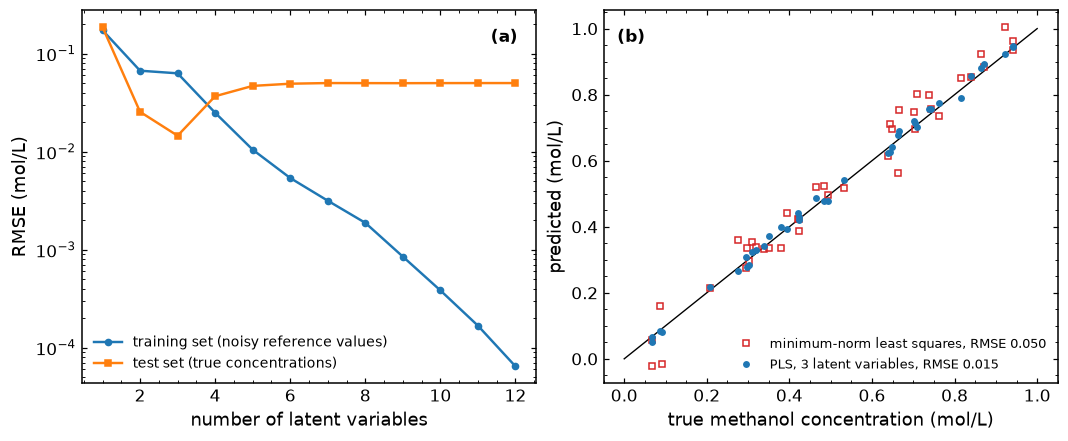

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.6, 3.9))
k_all = np.arange(1, 13); tr_all, te_all = [], []
for k_lv in k_all:
    fit_k = dim_reduction.pls1_nipals(X_nir, y_meoh, n_components=int(k_lv))
    tr_all.append(np.sqrt(np.mean((fit_k["y_pred"] - y_meoh) ** 2)))
    te_all.append(np.sqrt(np.mean((X_test @ fit_k["coef"] + fit_k["intercept"] - y_test) ** 2)))
ax1.semilogy(k_all, tr_all, "o-", ms=4, label="training set (noisy reference values)")
ax1.semilogy(k_all, te_all, "s-", ms=4, label="test set (true concentrations)")
ax1.set_xlabel("number of latent variables"); ax1.set_ylabel("RMSE (mol/L)"); ax1.legend(fontsize=9, loc="lower left"); panel_label(ax1, "(a)", x=0.9)
ax2.plot([0.0, 1.0], [0.0, 1.0], "k-", lw=0.9)
ax2.plot(y_test, y_pred_ols, "s", ms=4, mfc="none", color="C3", label=f"minimum-norm least squares, RMSE {rmse_ols:.3f}")
ax2.plot(y_test, y_pred_pls, "o", ms=3.5, color="C0", label=f"PLS, 3 latent variables, RMSE {rmse_pls:.3f}")
ax2.set_xlabel("true methanol concentration (mol/L)"); ax2.set_ylabel("predicted (mol/L)"); ax2.legend(fontsize=8.5, loc="lower right"); panel_label(ax2, "(b)")
plt.show()

**Figure 8.2.** (a) The error of the PLS model against the number of latent variables. On the training set it keeps falling; on the test set it is smallest at three, the number of absorbing species. (b) Predictions for 40 new samples from the three-variable model and from the least-squares solution that fits the 35 training samples exactly.

**What Demonstration 4 shows.** With fewer than three components the model cannot separate the three overlapping absorbers. The test error is smallest at $k = 3$ ($0.0145\;\mathrm{mol/L}$). With more components the training error keeps falling while the test error rises to $0.037$ and then $0.05\;\mathrm{mol/L}$, and the norm of the regression vector grows from $0.55$ to between 4 and 5: the extra components fit the noise.

---

## Inside the algorithm
Below we verify our by-hand NIPALS matrices $\mathbf{W}, \mathbf{P}, \mathbf{q}$ and closed-form inversion $\hat{\boldsymbol{\beta}} = \mathbf{W}(\mathbf{P}^\top\mathbf{W})^{-1}\mathbf{q}$ against `dim_reduction.pls1_nipals`.

In [8]:
heading("Inside the Algorithm: By-Hand W(P^T W)^(-1)q vs. the Library")
q_hand = np.linalg.solve(T_scores.T @ T_scores, T_scores.T @ (y_meoh - np.mean(y_meoh)))
beta_pls_hand = W_m @ np.linalg.solve(P_m.T @ W_m, q_hand)
diff_pls = float(np.max(np.abs(beta_pls_hand - pls3["coef"])))
print("by hand (pure NumPy) beta[:5]:", np.round(beta_pls_hand[:5], 6))
print("library (engml_2_applied)      beta[:5]:", np.round(pls3["coef"][:5], 6))
print(f"Max discrepancy              : {diff_pls:.2e}")
assert diff_pls < 1e-14


Inside the Algorithm: By-Hand W(P^T W)^(-1)q vs. the Library
by hand (pure NumPy) beta[:5]: [ 0.00387   0.001105 -0.003724 -0.004848 -0.000431]
library (engml_2_applied)      beta[:5]: [ 0.00387   0.001105 -0.003724 -0.004848 -0.000431]
Max discrepancy              : 5.55e-17


## Exercises

1. **Verify a result.** Verify on a tall well-conditioned design matrix $\mathbf{X} \in \mathbb{R}^{40 \times 4}$ that `pls1_nipals(X, y, n_components=4)` (when $k = d$) converges to the exact ordinary least squares regression coefficients and intercept to within $10^{-11}$.
2. **Find how it fails.** Make methanol a minor absorber: replace its pure spectrum (`E_pure[1]`) by a weak band, `0.08 * np.exp(-0.5 * ((wl - 1250.0) / 30.0) ** 2)`, rebuild the spectra, and compare PCR and PLS1 with 1, 2 and 3 components for the methanol concentration. Does PLS1 find the minor component with fewer components than PCR?
3. **Write it yourself.** Implement **variable importance in projection (VIP)** scores `pls_vip_scores(X: np.ndarray, y: np.ndarray, n_components: int = 3) -> np.ndarray`, defined by $\mathrm{VIP}_j = \sqrt{d \sum_{a=1}^k (q_a^2 \mathbf{t}_a^\top\mathbf{t}_a)\,w_{j,a}^2 / \sum_{a=1}^k q_a^2 \mathbf{t}_a^\top\mathbf{t}_a}$, which satisfies the exact sum-of-squares identity $\frac{1}{d}\sum_{j=1}^d \mathrm{VIP}_j^2 = 1.0$. Verify on `(X_nir, y_meoh)` that $\frac{1}{d}\sum_j \mathrm{VIP}_j^2 = 1.0$ and that the peak VIP wavelength matches the true methanol absorption band ($1680\;\mathrm{nm}$ or $2100\;\mathrm{nm}$).

The cell below works Exercise 1 as a first check; all three are solved in the solutions notebook of this lecture.

In [9]:
heading("Exercise 1: Exact Equivalence of Full-Rank PLS1 (k = d) and OLS")
X_tall = rng.normal(0.0, 1.0, size=(40, 4))
y_tall = X_tall @ np.array([1.5, -0.8, 2.2, -0.4]) + 3.0 + rng.normal(0.0, 0.1, size=40)
pls_d = dim_reduction.pls1_nipals(X_tall, y_tall, n_components=4)
w_ols_d = np.linalg.lstsq(np.column_stack([np.ones(40), X_tall]), y_tall, rcond=None)[0]

assert np.allclose(pls_d["coef"], w_ols_d[1:], atol=1e-11)
assert np.isclose(pls_d["intercept"], w_ols_d[0], atol=1e-11)
print("Verified exact equivalence of PLS1 (k = d = 4) and OLS:", np.round(pls_d["coef"], 5))


Exercise 1: Exact Equivalence of Full-Rank PLS1 (k = d) and OLS
Verified exact equivalence of PLS1 (k = d = 4) and OLS: [ 1.49605 -0.81297  2.21348 -0.40585]
